

# Table of Contents

**Phase 1: Data Preparation and Metrics Definition**
- 1.1 Preprocessing and Data Cleaning
- 1.2 Definition of Key Metrics
- 1.3 Network Construction and Representation

**Phase 2: Outbreak Detection and Analysis**  
- 2.1 Community Exploration and Structure Analysis	
- 2.2 Outbreak Identification and Characterization

**Phase 3: Propagation and Diffusion Analysis**  
- 3.1 Cascade Tracing and Flow Dynamics
- 3.2 Immunity and Containment Effects

**Phase 4: Lifecycle and Evolution Study**  
- 4.1 Detection of Cycles and Key Events
- 4.2 Evolutionary Tracking Over Time

**Phase 5: Validation and Synthesis of Results**  
- 5.1 Cross-Validation and Robustness Checks
- 5.2 Final Interpretation and Conclusions


### **Install Requirements**

In [1]:
%pip install -r pip_requirements.txt

Note: you may need to restart the kernel to use updated packages.


### **Imports**

*Note that you need a 'Data' folder containing the 4 datasets defined in the README. This folder should be placed at the same level as src and tests directories.*

In [2]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *


Computing SOURCE (aggressor) features...


# Project pipeline




---
# Phase 1: Data Preparation

## 1.1 Preprocessing & Cleaning


### Data Quality Checks, Unification & Standardization

We import and preprocess data through the following steps:

1. Import TSV files and expand PROPERTIES column into 86 features
2. Merge together both title and body datasets in a unified dataset, with `TYPE` to retain information of source.
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and chronologically reorder the combined dataset (temporal integrity was altered by merging)
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap

The steps are performed using functions defined in `init_data.py`.

In [3]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [4]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


## 1.2 Definition of Key Metrics



**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

### 1.2.1 Core Toxicity Metric

Our first fundamental preliminary step is to calculate a reliable and accurate metric of toxicity of each subreddit's post.

By toxicity, we refer to patterns of communication or behavior that create a hostile, disrespectful, or harmful environment for participants. This can include insults, harassment, hate speech, excessive negativity, or attempts to provoke conflict. Toxicity reduces constructive discussion, discourages participation, and can damage the overall health and cohesion of the community.

The majority of these characteristics are captured by some of the 86 properties that are already includeded in our dataset. Let's understand what they actually represent.

**Properties 1 to 18** capture surface-level linguistic and structures of the text. They measure the basic composition and readability of a message, including its length, complexity, and word or sentence structure. They include metrics such as character and word counts, fractions of different character types (letters, digits, punctuation, etc.), sentence length averages, and readability scores. Together, they provide a quantitative snapshot of how the text is written rather than what it expresses.

**Properties 19 to 21** represent sentiment analysis metrics, derived using the VADER (Valence Aware Dictionary and sEntiment Reasoner) model. They aim to measure the emotional polarity of the text. It includes the Positive Sentiment, Negative Sentiment and Compound Sentiment. These features reflect the emotional valence of the language used.

**Properties 22 to 86** are purely lexicon-based ratios, derived using a text analyis tool called Linguistic Inquiry and Word Count (LIWC). Each LIWC represent the proportion of words in a text that belong to a certain lexicon: LIWC_X = (nb words in lexicon X) / (total nb words). While useful to see the presence of a certain vocubulary in a post, they remain purely lexical and doesn't treat emotion or sentiment in any way.

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_SCORE</code>: continuous metric that measures the toxicity intensity in a subreddit post, using the 86 existing properties 
</div>

(Function also implemented in `compute_toxicity_score.py` in `utils` module.)

**Properties that are interesting for capturing toxicity**

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | `Number of UPPERCASE words`, `Readability index`... 

However, above all these textual properties, we also consider true **negativity** of a post to be a **necessary** component for it to be toxic.

**The problem: none of the 86 properties provides a reliable measure of emotional negativity in a post.** 

While the VADER scores seemed promising (optimized for social media texts and posts), they mainly work like a LIWC score and calculate emotion of the **language** that was used (like an advanced lexical repertory of words that are conventionally considered negative or harmful on social platforms).

This cannot be considered an accurate measure of negativity in our context. For example, some shortfalls of lexical metrics include:

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like “grenade” or “headshots.” These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).

**Good news: `LINK_SENTIMENT` solves this problem.**

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

We want to explore what are the properties that play a determinant role in negativity. To do so, we compare the normalized property means between positive and negative links (normalized because some properties have different scales and centers). Look which are the most significantly different for positive VS negative links.

The threshold for significant difference was arbitrrary set to 0.25 to retain around 20 properties.

,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,FRACTION_OF_WHITE_SPACES,FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC,NUMBER_OF_WORDS,NUMBER_OF_UNIQUE_WORDS,NUMBER_OF_LONG_WORDS_AT_LEAST_6_CHARACTERS,...,LIWC_ACHIEV,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER
min,7.0,7.0,0.016340,0.00000,0.000505,0.000126,0.001277,1.0,1.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
median,107.0,94.0,0.777778,0.00000,0.083333,0.146341,0.062554,18.0,17.0,4.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
max,41239.0,39369.0,0.994208,0.85077,0.993485,0.880000,0.917808,7600.0,2693.0,1978.0,...,0.555556,0.9,0.555556,0.916667,0.75,0.6,0.769231,0.967742,0.6,0.6


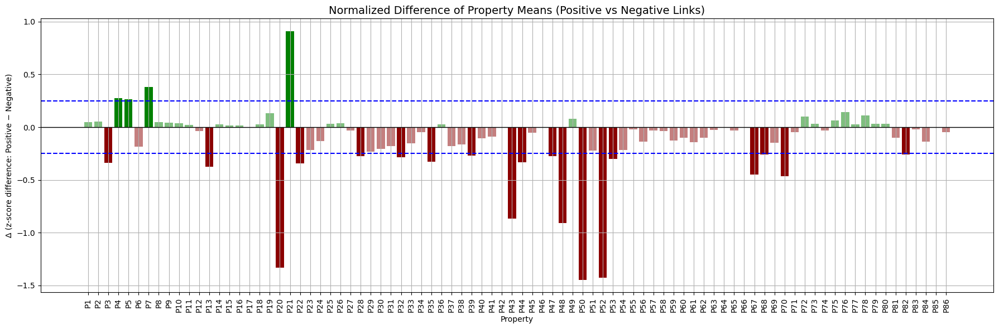

Found 4 properties higher for positive links (zΔ > 0.25):
- (z_diff = 0.273) 	 FRACTION_OF_DIGITS
- (z_diff = 0.262) 	 FRACTION_OF_UPPERCASE_CHARACTERS
- (z_diff = 0.382) 	 FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC
- (z_diff = 0.911) 	 COMPOUND_SENTIMENT_CALCULATED_BY_VADER

 Found 19 properties higher for negative links (zΔ < -0.25):
- (z_diff = -0.34) 	 FRACTION_OF_ALPHABETICAL_CHARACTERS
- (z_diff = -0.375) 	 FRACTION_OF_STOPWORDS
- (z_diff = -1.33) 	 NEGATIVE_SENTIMENT_CALCULATED_BY_VADER
- (z_diff = -0.346) 	 LIWC_FUNCT
- (z_diff = -0.272) 	 LIWC_SHEHE
- (z_diff = -0.287) 	 LIWC_VERBS
- (z_diff = -0.326) 	 LIWC_PRESENT
- (z_diff = -0.27) 	 LIWC_CONJ
- (z_diff = -0.867) 	 LIWC_SWEAR
- (z_diff = -0.33) 	 LIWC_SOCIAL
- (z_diff = -0.273) 	 LIWC_HUMANS
- (z_diff = -0.909) 	 LIWC_AFFECT
- (z_diff = -1.448) 	 LIWC_NEGEMO
- (z_diff = -1.425) 	 LIWC_ANGER
- (z_diff = -0.302) 	 LIWC_SAD
- (z_diff = -0.451) 	 LIWC_BIO
- (z_diff = -0.259) 	 LIWC_BODY
- (z_diff = -0.465

In [5]:
threshold_zdiff = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold_zdiff)

Combining our qualitative choice of what defines toxicity with the will to mainly use properties that prove to appear in negative hyperlinks only, below is our final choice of the toxicity_metric. Note that all these properties represent ratios (values between 0 and 1).

Our `TOXICITY_SCORE` metric will be a combination of all these properties.

For this initial exploration, we define the continuous `TOXICITY_SCORE` as a **weighted average** of the retained properties. The current weights are derived from intuitive coefficients based on established literature in toxicity and destructive discourse, prioritizing a fast, interpretable metric that reflects our working definition of toxicity. While this approach is **simple and effective for preliminary analysis**, in the future **we plan to explore more advanced options**, such as performing Logistic Regression on a small, manually labeled subset of the data to derive statistically optimized weights, for example. It can also turn out better to do more than a simple linear combination and we might use interaction terms and non-linear functions of property scores.

Mathematically, `TOXICITY_SCORE` will therefore range from -1 to 1.

In [6]:
interactions_df["LINK_SENTIMENT_ADJUST"] = (1 - (interactions_df["LINK_SENTIMENT"] + 1)/2)/4

tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [0, "LINK_SENTIMENT_ADJUST"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [0, "LIWC_AFFECT"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum() 
#display(tox_props)

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.008514
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title,0.0,0.000000
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body,0.0,0.019065
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title,0.0,0.021591
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body,0.0,0.010149


Let's visualize our new metric empirical distribution.

count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


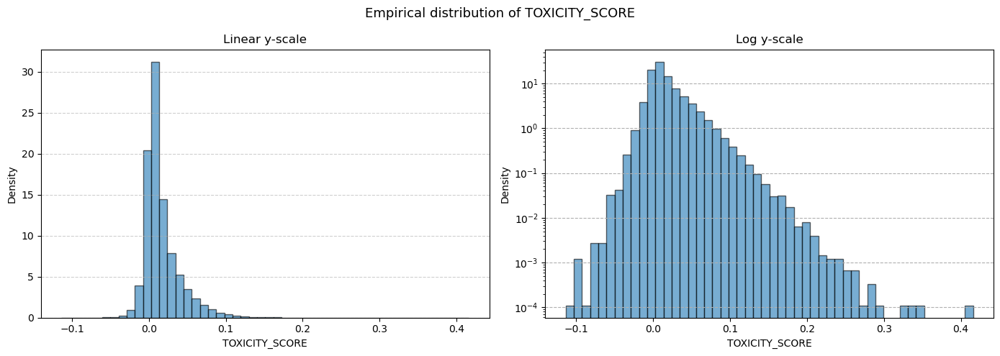

In [7]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

Although theoretically ranging from -1 to 1 by construction, we observe that `TOXICITY_SCORE` only take values between approx. -0.1 and 0.4. This is however not a problem because we later introduce multiple centering and scaling operations.

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret it directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score high? In other words, is this message toxic?"

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_CAT</code>: categorical metric that classifies posts as toxic (0) or toxic (1), after passing a threshold on <code>TOXICITY_SCORE</code>. 
</div>

For now, the threshod above which messages are flagged as toxic is the quantile-75 of the toxicity scores distribution. That is, **we mark as significantly toxic the top 25% messages with highest score**. While this is a reasonable and consistent approach, this threshold can be better set in the future and we will probably explore better ways to classify messages.

In [8]:
threshold_toxicity = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", threshold_toxicity)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= threshold_toxicity).astype(int)

75% quantile threshold: 0.02368686868687879


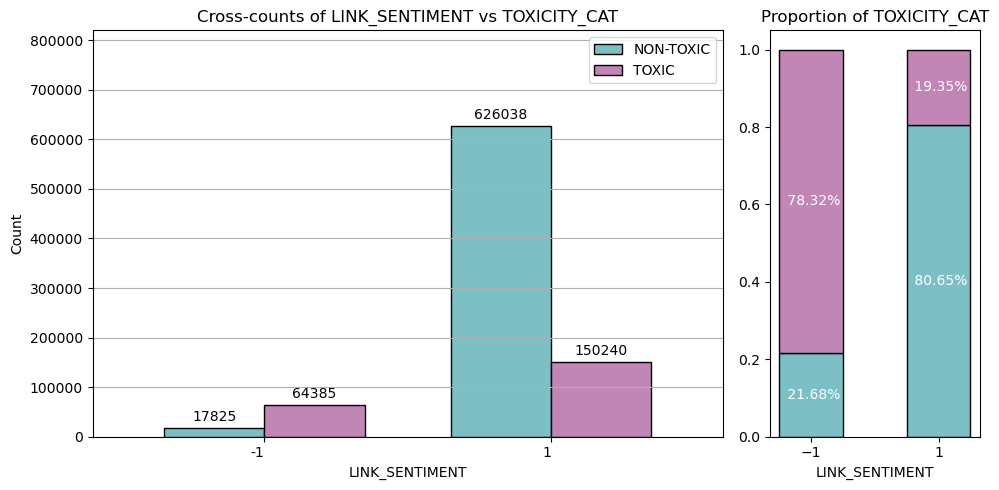

In [9]:
cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, looking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Negative messages are much more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

In [10]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

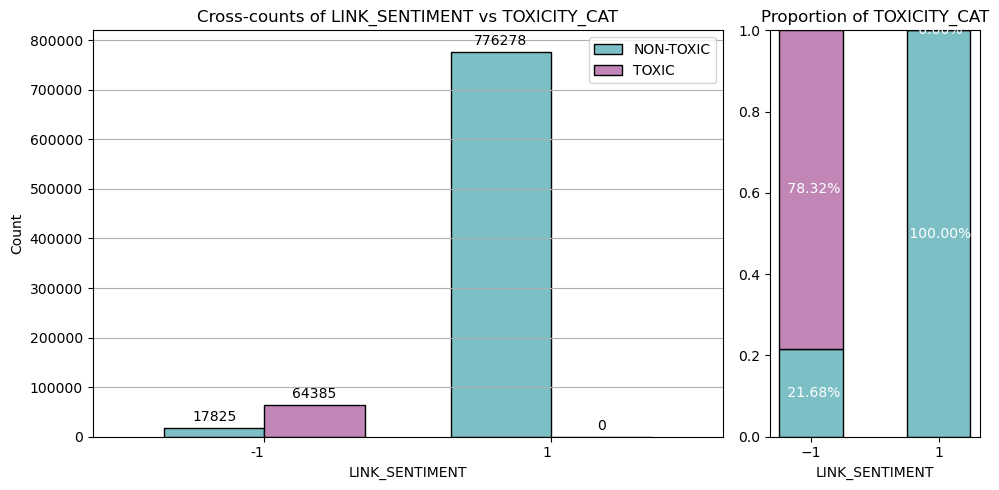

In [11]:
# Sanity check (to verify elimination of false positives)
cross_count_SENTIMENT_TOXICITY(interactions_df)

Let's see how much toxic posts we detected over the entire period. The following plot aggregates over all subreddits and averages monthly, but acts as a quick sanity check to see if the count stays coherent over time.

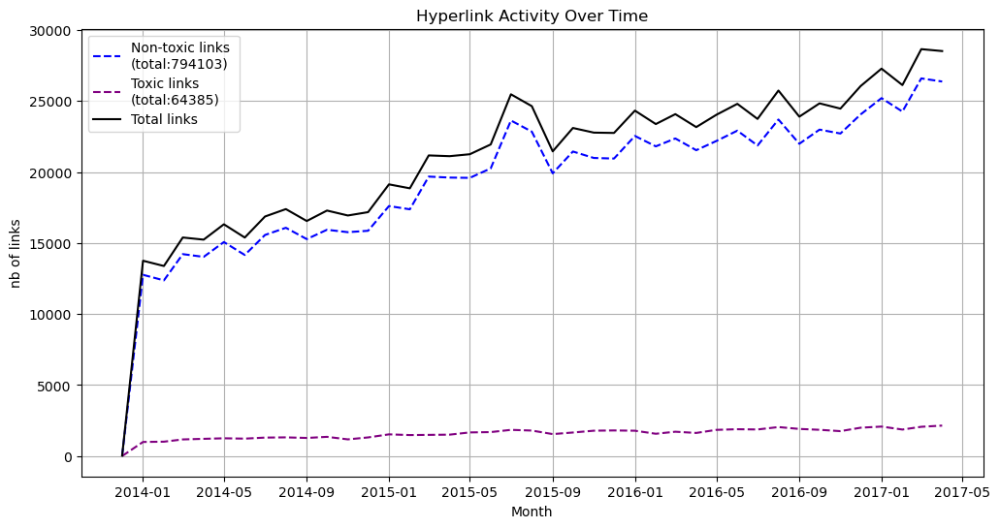

In [12]:
interactions_df["year_month"] = interactions_df["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

links_over_time_sent = (
    interactions_df.groupby(["year_month", "TOXICITY_CAT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="TOXICITY_CAT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)
toxicity_counts = interactions_df["TOXICITY_CAT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[0], label=f"Non-toxic links \n(total:{toxicity_counts[0]})", color='blue', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Toxic links \n(total:{toxicity_counts[1]})", color='purple', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="black")

plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

### 1.2.2 Supporting and Derived Metrics 

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

 
**Count Metrics:**

(Following metrics can be restricted to a specified time window)
- `TOXICITY_COUNT`: Number of posts classified toxic during the time window:
    - if the time window is `'overall'`, this is simply the global count of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts computed for each month or year separately (e.g., for `'monthly', the count of toxic posts in June 2023).
- `NON_TOXICITY_COUNT`: Number of posts classified toxic during the time window:
    - if the time window is `'overall'`, this is simply the global count of non-toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of non-toxic posts computed for each month or year separately (e.g., for `'monthly', the count of non-toxic posts in June 2023).
- `TOTAL_COUNT`: Number of posts (toxic + non-toxic) during the time window:
    - if the time window is `'overall'`, this is simply the global count of posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of posts computed for each month or year separately (e.g., for `'monthly', the count of posts in June 2023).

These metrics also act as a foundation for the following rate-based metrics.`



</div>

In [13]:
toxic_count = compute_toxic_count(interactions_df, time_window='yearly')
non_toxic_count = compute_non_toxic_count(interactions_df, time_window='yearly')
total_count = compute_total_count(interactions_df, time_window='yearly')

count_metrics_df = pd.concat([toxic_count, non_toxic_count, total_count], axis=1)
count_metrics_df.columns = ['TOXICITY_COUNT', 'NON_TOXICITY_COUNT', 'TOTAL_COUNT']
count_metrics_df.head()

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:301: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].lt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:339: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y").size()


,TOXICITY_COUNT,NON_TOXICITY_COUNT,TOTAL_COUNT
TIMESTAMP,,,
2013-12-31,3,31,34
2014-12-31,46272,145417,191689
2015-12-31,65671,198000,263671
2016-12-31,73314,219202,292516
2017-12-31,26660,83918,110578


<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Rate-Based Metrics:**

To quantify frequency and ratios of toxic behavior in a given time window.

- `TOXICITY_RATE`: Proportion of toxic source messages in a time window, calculated as `TOXIC_COUNT` divided by `TOTAL_COUNT` (Range: 0–1):
    - if the time window is `'overall'`, this is simply the overall proportion of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the proportion of toxic posts computed for each month or year separately (e.g., for `'monthly', the proportion of toxic posts in June 2023).
- `TOXICITY_ODDS`: Alternative measure calculated as `TOXIC_COUNT` divided by `NON_TOXIC_COUNT`. Could be used to model odds and log-odds for logistic models in the following steps of the project:
    - if the time window is `'overall'`, this is simply the overall odds of toxic posts over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the odds of toxic posts computed for each month or year separately (e.g., for `'monthly', the odds of toxic posts in June 2023).
</div>

In [14]:
toxicity_rate = compute_toxicity_rate(interactions_df, time_window='yearly')
toxicity_odds = compute_toxicity_odds(interactions_df, time_window='yearly')

rate_metrics_df = pd.concat([toxicity_rate, toxicity_odds], axis=1)
rate_metrics_df.columns = ['TOXICITY_RATE', 'TOXICITY_ODDS']
rate_metrics_df.head()

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:339: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y").size()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-202

,TOXICITY_RATE,TOXICITY_ODDS
TIMESTAMP,,
2013-12-31,0.088235,0.096774
2014-12-31,0.241391,0.318202
2015-12-31,0.249064,0.331672
2016-12-31,0.250632,0.334459
2017-12-31,0.241097,0.317691


<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Rollingly Normalized Score Metric:**

<code>TOXICITY_SCORE_ROLLZ</code>: continuous metric <code>TOXICITY_SCORE</code>, normalized on a lagging rolling window (that is, at each date it is centered on its rolling average and divided by its rolling std). No look-ahead bias is applied (the metric can be used for future prediction task just like the original score). For now, we keep the temporal window to 1 year.

The use of this last metric is to facilitate detecting **toxicity bursts**: when <code>TOXICITY_SCORE_ROLLZ</code> passes above a threshold (for example 2), it means that this post is more toxic by 2*std than the toxicity mean of all posts of last year. 
</div>

In [15]:
rolling_window = "365D" # The time window can be adjusted as needed

interactions_df["TOXICITY_SCORE_ROLLZ"] = (
    (interactions_df["TOXICITY_SCORE"] -
     interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].mean())
    / interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].std()
)

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**General Normalization Metrics:**

To contextualize toxicity scores within recent history (i.e., the considered time window).

- `BASE_TOXICTY_OFFSET`: Mean of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is simply the global mean of the score over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the mean toxicity score computed for each month or year separately (e.g., for `'monthly'`, the mean toxicity score of all posts in June 2023).
- `TOXICITY_STD`: Standard deviation of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is simply the global std of the score over the entire dataset.
    - if the time window is `'monthly'` or 'yearly', this is the std toxicity score computed for each month or year separately (e.g., for `'monthly'`, the std of toxicity score of all posts in June 2023).
- `TOXICITY_CONTEXT_ZSCORE`: Z-score of `TOXICITY_SCORE` within the time window:
    - if the time window is `'overall'`, this is each post's toxicity score standardized using the global mean and std.
    - if the time window is `'monthly'` or `'yearly'`, this is each post's toxicity score standardized using the mean and std of the corresponding month or year (e.g., for `'monthly'`, all posts in June 2023 are standardized using the mean and std of toxicity scores of June 2023).
</div>



In [16]:
base_offset = compute_base_toxicity_offset(interactions_df, 'yearly')
tox_std = compute_toxicity_std(interactions_df, 'yearly')
context_zscore = compute_toxicity_context_zscore(interactions_df, 'yearly')

gen_norm_metrics_df = pd.concat([base_offset, tox_std], axis=1)
gen_norm_metrics_df.columns = ['BASE_TOXICITY_OFFSET', 'TOXICITY_STD']

gen_norm_metrics_df.head(10)

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:110: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].mean()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:158: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].std()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:110: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP").resample("Y")["TOXICITY_SCORE"].mean()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils

,BASE_TOXICITY_OFFSET,TOXICITY_STD
TIMESTAMP,,
2013-12-31,0.009410,0.019562
2014-12-31,0.016029,0.022846
2015-12-31,0.016474,0.023332
2016-12-31,0.016527,0.023819
2017-12-31,0.016097,0.023829


In [17]:
context_zscore.head()

0   -0.045794
1   -0.481001
2    0.493553
3    0.622692
4    0.037780
dtype: float64

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">

**Directional Metrics:**

These metrics are subreddit-specific and will allow to explore community behaviors in a given time window.

- `TOXICITY_OUT`: Toxic links sent by a subreddit (aggressor behavior) in a time window:
    - if the time window is `'overall'`, this is simply the overall count of toxic posts sent by the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts sent by the subreddit computed for each month or year separately (e.g., for `'monthly', the count of toxic posts sent by the subreddit in June 2023).
- `TOXICITY_IN`: Toxic links received by a subreddit (victim/target behavior) in a time window:
    - if the time window is `'overall'`, this is simply the overall count of toxic posts received by the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of toxic posts received by the subreddit computed for each month or year separately (e.g., for `'monthly', the count of toxic posts received by the subreddit in June 2023).
- `TOXICITY_BALANCE`: Net toxicity = `TOXICITY_OUT - TOXICITY_IN` in a time window:
    - if the time window is `'overall'`, this is simply the overall net toxicity of the subreddit over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the net toxicity of the subreddit computed for each month or year separately (e.g., for `'monthly', the net toxicity of the subreddit in June 2023).
- `RECIPROCAL_TOXICITY`: Bidirectional toxic relationships between subreddit pairs which corresponds to the number of bidirectional edges in the toxic interaction graph in a time window:
    - if the time window is `'overall'`, this is simply the overall count of bidirectional toxic edges between a selected subreddit and its pairs over the entire dataset.
    - if the time window is `'monthly'` or `'yearly'`, this is the count of bidirectional toxic edges between a selected subreddit and its pairs computed for each month or year separately (e.g., for `'monthly', the count of bidirectional toxic edges between subreddit pairs in June 2023).
</div>

In [18]:
toxicity_out_nfl = compute_toxicity_out(interactions_df, subreddit_name='nfl', time_window='yearly')
toxicity_in_nfl = compute_toxicity_in(interactions_df, subreddit_name='nfl', time_window='yearly')
toxicity_balance_nfl = compute_toxicity_balance(interactions_df, subreddit_name='nfl', time_window='yearly')

directional_metrics_nfl_df = pd.concat([toxicity_out_nfl, toxicity_in_nfl, toxicity_balance_nfl], axis=1)
directional_metrics_nfl_df.columns = ['TOXICITY_OUT_NFL', 'TOXICITY_IN_NFL', 'TOXICITY_BALANCE_NFL']
directional_metrics_nfl_df.head()

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\compute_metric_utils.py:263: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  series = data.set_index("TIMESTAMP")["TOXICITY_SCORE"].gt(TOXICITY_THRESHOLD).resample("Y").sum()
c:\Users\aksel\Documents\EPF

,TOXICITY_OUT_NFL,TOXICITY_IN_NFL,TOXICITY_BALANCE_NFL
TIMESTAMP,,,
2013-12-31,0,1,-1
2014-12-31,16,236,-220
2015-12-31,27,234,-207
2016-12-31,60,266,-206
2017-12-31,9,121,-112


### 1.2.3 Potential Metrics to implement

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px;  display: inline-block; width: 90%; box-sizing: border-box;">
 
**Advanced Linguistic Metrics:**

To focus on **specific properties** of what was used to define toxicity. Could be useful and interesting when analysing the propagation of the negativity among subreddits.

- `PERSONAL_ATTACK_SCORE`: LIWC_You + LIWC_Negemo combinations.
- `RATIONAL_DISCOURSE_SCORE`: LIWC_CogMech + LIWC_Cause. 
- `COMPLEXITY_SCORE`: Readability + word length + vocabulary richness.

</div>

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
 
**Temporal Metrics:**
- `TOXICITY_VELOCITY`: Rate of change in toxicity over time (Δtoxicity_rate / Δtime)
- `TOXICITY_ACCELERATION`: Second derivative (change in velocity)
- `TOXICITY_PERSISTENCE`: Duration of sustained toxic behavior (consecutive toxic periods)

</div>

## 1.3 Network Construction and Representation

1. Build temporal network snapshots (monthly/yearly windows as shorter windows seem unreasonable given the data)  
2. Build directed graphs for each time period
3. Compute node edge attributes: degrees, toxicity metrics, network centrality measures, eigenvector centrality
4. Store as adjacency lists or graph objects for analysis

### 1.3.1 Computing overall mean toxicity score

To get an overall idea of whether we can detect clusters of toxic subreddits, we compute the mean toxicity score of the interactions going out of each subreddit, and use the embeddings to map them.

In [19]:
# === Compute mean toxicity for each source subreddit ===
mean_toxicity = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["TOXICITY_SCORE"]
    .mean()
    .rename("mean_toxicity_score")
)

# === Quick sanity check ===
print(mean_toxicity.head())
print(f"\nTotal subreddits with data: {mean_toxicity.ne(0).sum()} / {len(mean_toxicity)}")

SOURCE_SUBREDDIT
007                 0.000000
07scape             0.015126
07thexpansion       0.025000
098f6bcd4621d373    0.007576
0________0          0.010101
Name: mean_toxicity_score, dtype: float64

Total subreddits with data: 53420 / 55863


### 1.3.2 Mapping most active subreddits mean toxicity score

To obtain a readable and interpretable map (with not too many subreddits), we only keep active subreddits (the ones that have more than 20 outgoing interactions over the time period).
We use UMAP (Uniform Manifold Approximation and Projection) to reduce the dimensionality of the embeddings (300) to a plottable 2D map, to see the proximity between subreddits based on their embedding representations. UMAP is a nonlinear dimensionality reduction technique that preserves both local and global structure in the data, making it well-suited for visualizing complex high-dimensional relationships between subreddits in a 2D space.

c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\network_utils.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  embeddings_df['x'] = embedding_2d[:, 0]
c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\network_utils.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#r

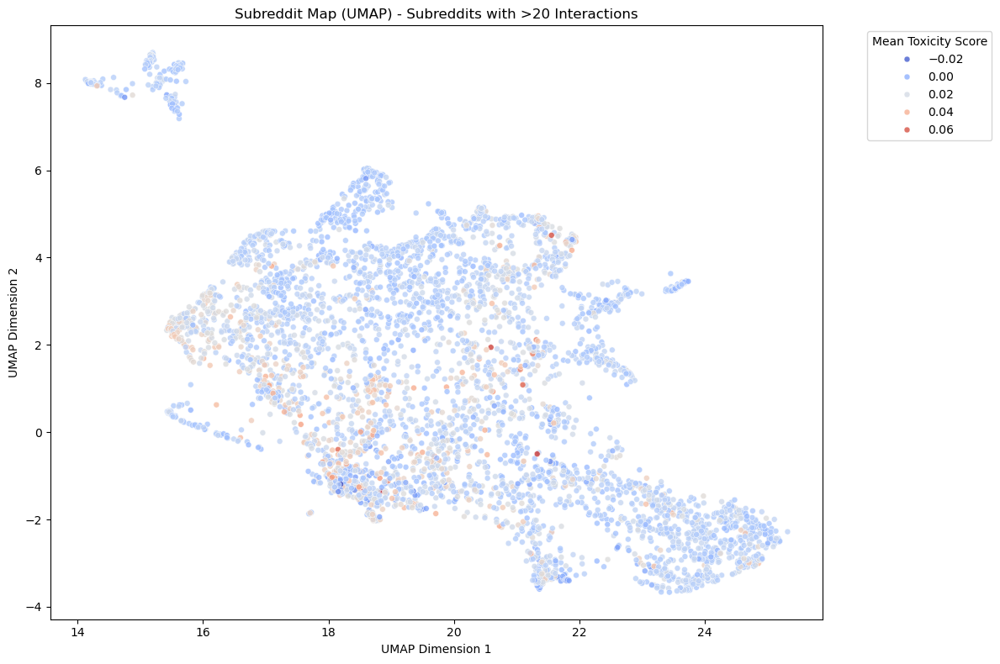

In [20]:
# Use utils function to filter active subreddits and get their embeddings
active_subs, filtered_embeddings = filter_active_subreddits(min_interactions=20)

# Reduce filtered embeddings from 3D to 2D
filtered_embeddings_2d = reduce_embeddings_2d(filtered_embeddings)

# Merge mean toxicity data
embeddings_with_toxicity = filtered_embeddings_2d.merge(
    mean_toxicity, left_on="SUBREDDIT", right_on="SOURCE_SUBREDDIT", right_index=True, how="left"
).fillna(0)

# === Plot ===
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=embeddings_with_toxicity,
    x="x", y="y",
    hue="mean_toxicity_score",
    palette="coolwarm",   
    s=25,
    alpha=0.8
)
plt.title("Subreddit Map (UMAP) - Subreddits with >20 Interactions")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Mean Toxicity Score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

We can already see that some areas have a higher proportion of subreddits with a moderately high mean toxicity score. 
This observation is very broad since it only considers the mean toxicity over the whole period (2.5 years): communities should be easier to observe over a smaller time period, if selected correctly.

### 1.3.3 Monthly evolution of toxicity score

We check whether we can decompose the data into monthly time series by taking advantage of the 'TIMESTAMP' column, still with the most active subreddits, and plot them using an animated UMAP. 
We compute the monthly mean outgoing toxicity score of each subreddit to see their evolution with time.

In [21]:
ani_monthly = animate_evolution(active_subs, filtered_embeddings, freq='M')
HTML(ani_monthly.to_jshtml())

c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\network_utils.py:86: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .groupby([pd.Grouper(key='TIMESTAMP', freq=freq), 'SOURCE_SUBREDDIT'])


This animation shows fluctuating toxicity scores for most subreddits, but also clusters who keep mostly toxic interactions throughout the whole time period (such as at the bottom left of the main island).

### 1.3.4 Weekly evolution of toxicity score

To later  be able to investigate cascades of toxicity with more precision, we try visualizing weekly evolution of toxicity scores

In [22]:
ani_weekly = animate_evolution(active_subs, filtered_embeddings, freq='W')
HTML(ani_weekly.to_jshtml())

Animation size has reached 21108633 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


The result is too heavy to be displayed entirely but shows that we are able to study weekly fluctuations of toxicity of subreddits within a certain time window (to be later determined for cascade analysis).

---
# Phase 2: Outbreak Detection and Analysis (started, to finish after P2)

## 2.1 Community Exploration and Structure Analysis
- Detect subreddit clusters (who interacts with whom?)
- Characterize each community's baseline behavior
- Track community changes over time

### 2.1.1 Using the Louvain algorithm

The Louvain algorithm is a community detection method that groups nodes in a network into clusters (communities) by maximizing modularity, a measure of how densely connected nodes are within communities compared to between them. In our case, we apply the Louvain algorithm to the toxic interaction graph, where nodes represent subreddits and weighted edges represent the number of toxic interactions between them. This allows us to identify clusters of subreddits that frequently exchange toxic messages, revealing potential toxic communities.

Graph built: 9752 nodes, 32224 toxic edges
Detected 1200 communities.
Detected 113 toxic communities.
     COMMUNITY_ID  SIZE
0               8     1
1              19     2
2              28     2
3              31     2
4              35     2
..            ...   ...
108          1190     1
109          1192     2
110          1194     2
111          1198     2
112          1199     2

[113 rows x 2 columns]
Biggest highly toxic community ID: 863
Number of subreddits in this community: 10


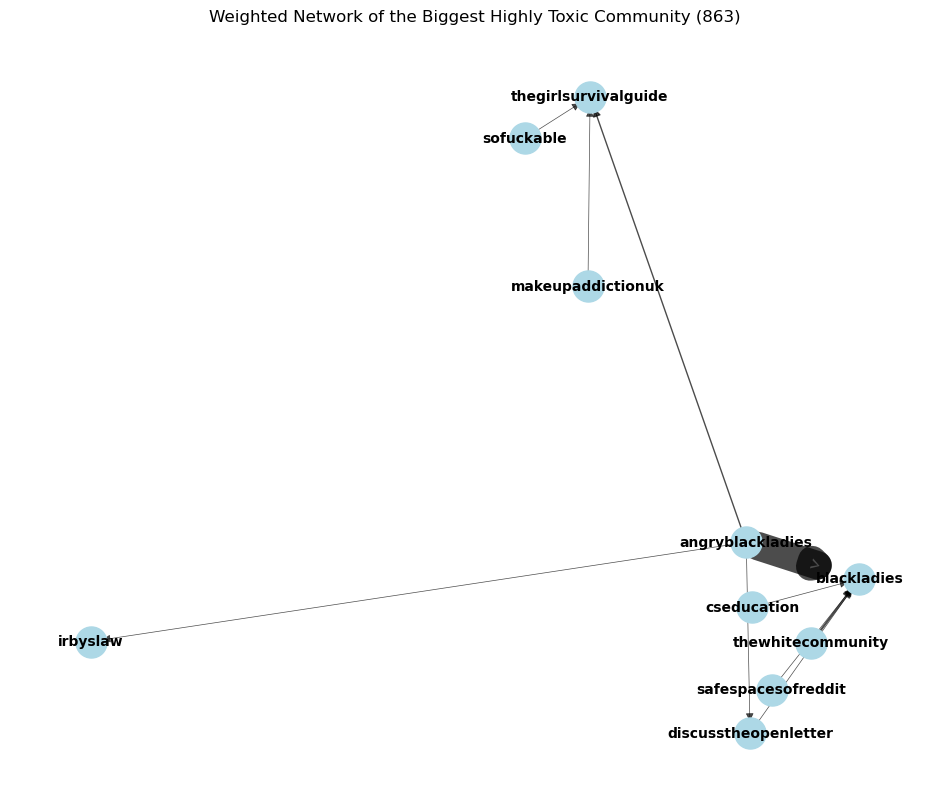

In [23]:
# Only select toxic interactions to build the graph to detect toxic communities
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1]  # keep only toxic interactions

# Find Louvain communities from toxic interactions and their number of interactions
community_df, toxic_interactions = louvain_communities(toxic_df)

# We consider communities with more than 30% toxic interactions as toxic
toxicity_threshold = 0.3

# Find toxic communities
community_df = get_toxic_communities(community_df, toxicity_threshold)

# Plot the biggest toxic community network
plot_biggest_toxic_community_network(community_df, toxic_interactions)

We observe that the Louvain algorithm mostly finds very small communities (1 or 2 subreddits). 
This is due to the fact that when using the full time period as we did here, toxic interactions are sparse and scattered across time, leading the Louvain algorithm to detect many small, isolated communities. By focusing on a shorter, well-chosen period where toxicity peaks (to be determined later), interactions are denser and more connected, making it easier to identify larger, more cohesive toxic communities.

## 2.2 Outbreak identification and Characterization
- **Detect outbreaks**: When toxicity suddenly spikes
- **Find origins (Patient-0)**: Which subreddit started it?
- **Measure impact**: How big did the outbreak get?


### 2.2.1 Data Focusing tool

In order to identify the patient 0, we first construct a tool capable of focusing on a time window and on links which contain a specific keyword. This allows us to dig into a more relevant part of the data, and therefore identify more easily trends in a given context. 

We highlight that this method is meant to help faster identification of trends, and that a more rigorous causal analysis will be conducted later on. This is important as this tool may focus too much on parts of the data, and thus eliminate precursors without eliminating their effect. In instance, the actual patient zero subreddit or community might not contain the chosen given in its name, leaving the possibility of having it as a precursor behind. The possibility of having the keyword in a subreddit name with no link is also possible (see example with 'nba', we get 'greeNBAypackers' as a related subreddit).

In [24]:
# Subreddit keyword to focus on
KEYWORD = "nba"

# Time Window to consider
# TIME_WINDOW = [date(2016, 6, 1), date(2017, 2, 1)] # TRUMP
TIME_WINDOW = [date(2015, 6, 1), date(2015, 8, 1)] # NBA

# Extract focused dadaframe
focused_df = extract_focused_df(interactions_df, KEYWORD, TIME_WINDOW)
focused_df.head(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE,TOXICITY_CAT,year_month,TOXICITY_SCORE_ROLLZ
293374,bestofrabsho,nba,37kkwhs,2015-06-01 06:52:48,1,46.0,41.0,0.760870,0.000000,0.217391,...,0.0,0.000000,0.0,0.0,title,0.00,0.010943,0,2015-06-01,-0.229211
293472,sneakers,nbamarketplace,383eris,2015-06-01 09:53:24,1,84.0,73.0,0.785714,0.000000,0.297619,...,0.0,0.000000,0.0,0.0,title,0.00,0.024784,0,2015-06-01,0.371469
293914,retiredusername,nba,38l1n6s,2015-06-01 21:03:45,1,34.0,31.0,0.794118,0.000000,0.147059,...,0.0,0.000000,0.0,0.0,title,0.00,0.005051,0,2015-06-01,-0.485011
294707,chibears,greenbaypackers,38bikys,2015-06-02 21:28:28,1,7001.0,6553.0,0.611341,0.123982,0.086273,...,0.0,0.000991,0.0,0.0,body,0.00,-0.005694,0,2015-06-01,-0.951057
294759,badeconomics,nba,38bxeis,2015-06-02 23:24:27,1,41.0,36.0,0.804878,0.000000,0.170732,...,0.0,0.000000,0.0,0.0,title,0.00,0.008658,0,2015-06-01,-0.328522
295010,nbacirclejerk,nbastreams,38e048s,2015-06-03 10:26:55,1,36.0,29.0,0.722222,0.000000,0.361111,...,0.0,0.000000,0.0,0.0,title,0.00,0.014731,0,2015-06-01,-0.065217
295354,seahawks,greenbaypackers,38fwkts,2015-06-03 17:47:04,1,4276.0,4117.0,0.654584,0.098223,0.047942,...,0.0,0.000000,0.0,0.0,body,0.00,-0.004901,0,2015-06-01,-0.916776
295458,subredditdrama,nba,38gw77,2015-06-03 21:00:00,-1,106.0,90.0,0.811321,0.000000,0.056604,...,0.0,0.000000,0.0,0.0,title,0.25,0.047456,1,2015-06-01,1.354760
295904,warriors,nba,38k6hc,2015-06-04 13:28:40,-1,921.0,798.0,0.741585,0.017372,0.041260,...,0.0,0.006289,0.0,0.0,body,0.25,0.026492,1,2015-06-01,0.445309
296497,nbacirclejerk,clevelandcavs,38okdos,2015-06-05 09:38:20,1,17.0,17.0,0.823529,0.000000,0.823529,...,0.0,0.000000,0.0,0.0,title,0.00,0.000000,0,2015-06-01,-0.704116


In this example we focus on the NBA keyword and over the course of two months from June 2015 to August 2015. For further information about how the extract_focused_df() function works, please refer to the associated 'identify_patient_zero_module.py' file. Note that the focused_df preserves the order of the given dataframe in entry, time in our case.

### 2.2.2 Analysis of specific subreddits interactions over a given time period
#### Number of daily interactions across each subreddit
We start by conducting a temporal analysis of all interactions, as source or as target. This allows us to identify interaction outbreaks, which will be further analyzed to see if they are positive, negative and/or toxic events.

There are 111 different subreddits acting as source.
There are 61 different subreddits acting as target.


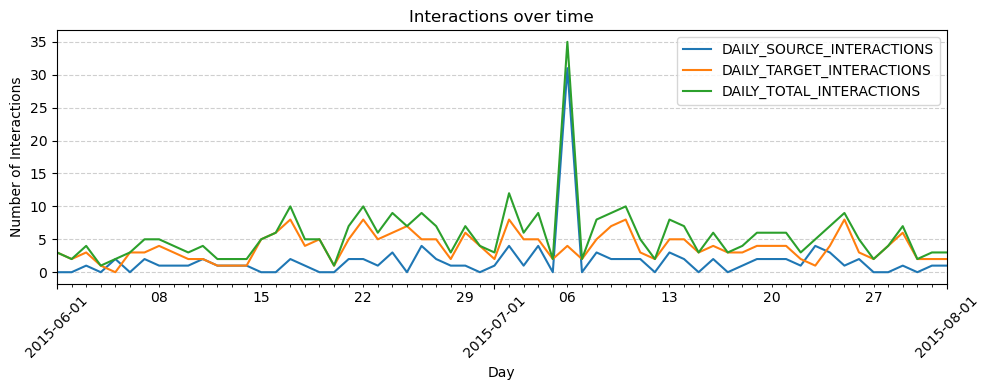

In [25]:
print("There are", len(focused_df["SOURCE_SUBREDDIT"].unique()), "different subreddits acting as source.")
print("There are", len(focused_df["TARGET_SUBREDDIT"].unique()), "different subreddits acting as target.")

# Count the number of daily interactions across all considered subreddits
daily_interaction_df = construct_daily_interaction_df(focused_df, KEYWORD, TIME_WINDOW)

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_interaction_df[["DAILY_SOURCE_INTERACTIONS",
                      "DAILY_TARGET_INTERACTIONS",
                      "DAILY_TOTAL_INTERACTIONS"]].plot(ax=ax)

# ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

We can see that a clear outbreak appears at the beginning of July 2015. We can also see that overall there are more targeted subreddits than source (a smaller amount of subreddits target more other subreddits). But during the outbreak, the number of source subreddits explodes, indicating a lot more different subreddits linked to the same (small) amount of target subreddits. This could be a toxic wave coming from various different communities towards a particular subreddit.

#### Number of interactions (as source and target) for each subreddit 

To further analyze which subreddits are potential victims and prosecutors, we show the amount of interactions (as source and as target) for the 8 most interactive subreddits.

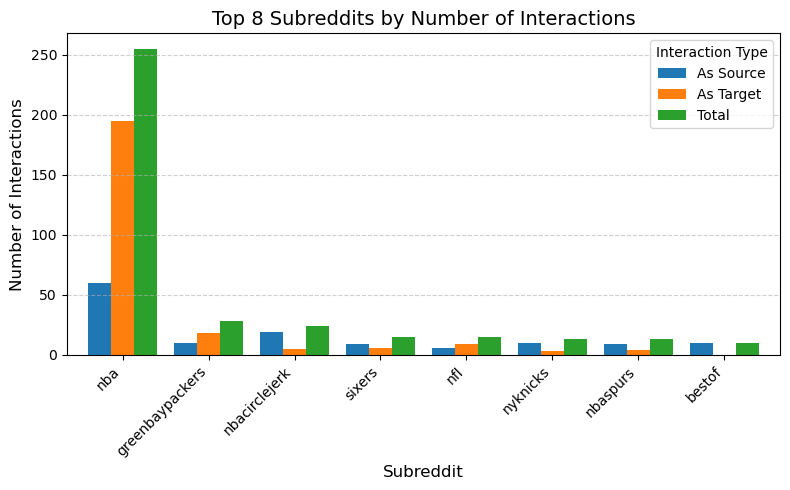

In [26]:
# Count the number of interaction as source and as target for each subreddit
sr_interaction_count_df = construct_interaction_count_df(focused_df)

# Choose the number of subreddits to plot
NB_TO_PLOT = 8

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_interaction_count_df.head(NB_TO_PLOT).plot(
    x="SUBREDDIT",
    y=["SOURCE_INTERACTIONS", "TARGET_INTERACTIONS", "TOTAL_INTERACTIONS"],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(["As Source", "As Target", "Total"], title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

A clear trend of links towards the 'nba' subreddit shows up, and some others like the 'nbacirclejerk' appears as one of the most targeting subreddit. Although, the balance between subreddits is not equitable and therefore if any toxic outbreak were to be happening, this would mean many attackers are implied rather than a specific subreddit. This makes the analysis more complicated, as we have to analyze the evolution interactions for each small subreddit separately. This is because we need to see if it is indeed a change in their behaviour or a recurrent interaction between the target and the source. 

### Number of negative daily interactions across each subreddit 

We now study the interactions themselves to see if they are negative and/or toxic based on as many criteria as wanted. Here, we take:
- 'LINK_SENTIMENT' == -1,
- 'TOXICITY_CAT' == 1

More criteria could be explored (and will in P3), like the 'TOXICITY_SCORE_ROLLZ', giving a broader view on the negative interactions. For the sake of simplicity, we will not consider more complete metrics, as the goal here is to present a tool made to roughly identify outbreaks and their nature (toxic or not). This is a preliminary study meant to go deeper in the causal analysis part.

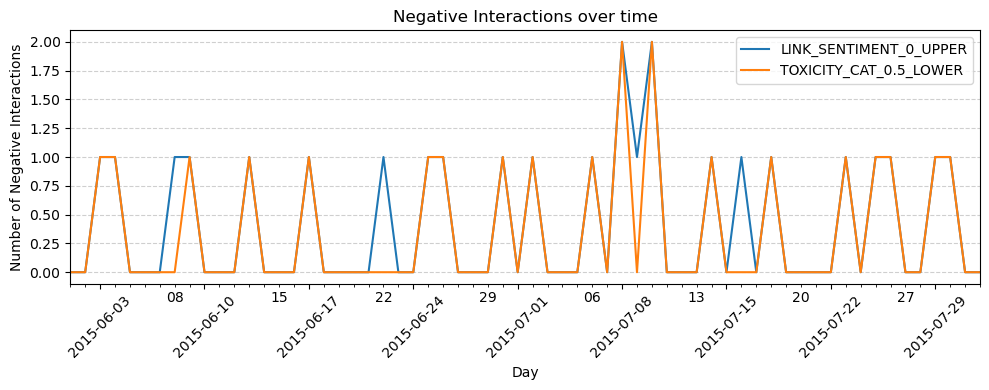

,LINK_SENTIMENT_0_UPPER,TOXICITY_CAT_0.5_LOWER
DAY,,
2015-06-01,0,0
2015-06-02,0,0
2015-06-03,1,1
2015-06-04,1,1
2015-06-05,0,0
...,...,...
2015-07-28,0,0
2015-07-29,1,1
2015-07-30,1,1


In [27]:
# Count the number of negative daily interactions across all considered subreddits
CRITERION = ["LINK_SENTIMENT",
             "TOXICITY_CAT"
             ]
THRESHOLDS = [0,
              0.5
              ]
UPPER = [True,
         False
        ]
daily_neg_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="DAY")

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_neg_interaction_df.plot(ax=ax)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Negative Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Negative Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Show dataframe for further investigation
daily_neg_interaction_df

It appears that during the outbreak, very few are actually detected (1 over 30 the same day, 2 over 30 the next day) as negative from LINK_SENTIMENT. Same goes for links detected as toxic (even less, which is expected since a toxic link is usually negative but a negative link is not necessarily toxic), which indicates a low amount of negativity/toxicity during the outbreak. As expected, LINK_SENTIMENT and TOXIC_CAT show very similar trends, and their relevance against each other will be analyzed and discussed later on (P3). 

In this example, we would tend to say this is not a major negative outbreak, and that these results are non-conclusive. This could be an outbreak with regular amount of toxicity, or simply a non-negative outbreak. Note again that this should and will be further analyzed to quantify the regular amount of toxicity and that relevance of criteria should be investigated (causal analysis in P3).

#### Number of negative aggregated interactions for each subreddit

Finally, we add a plot showing the number of negative interactions for each subreddit which allow us to highlight which subreddit is associated with negative links.

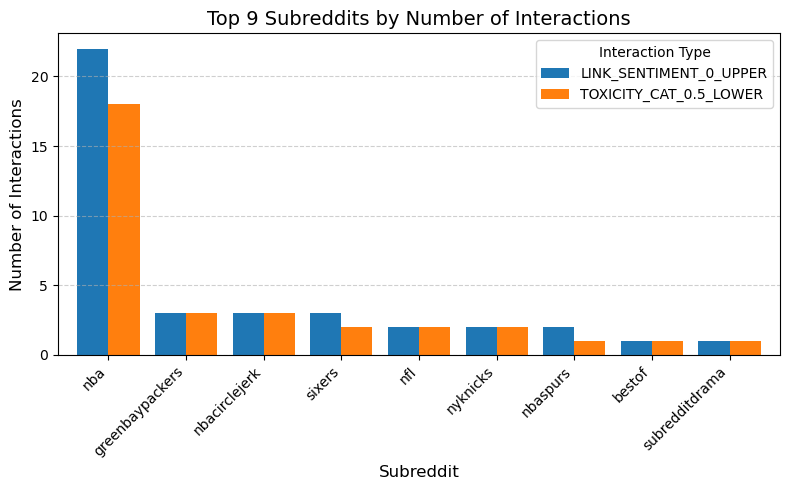

In [28]:
# Count the number of negative interactions for each considered subreddit

# Compute negative interactions as source
sr_neg_source_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="SOURCE_SUBREDDIT")
# Compute negative interactions as target
sr_neg_target_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="TARGET_SUBREDDIT")
# Add interactions and sort them by total
sr_neg_interaction_df = smart_df_add(sr_neg_source_interaction_df, sr_neg_target_interaction_df)
sr_neg_interaction_df["TOTAL_NEGATIVE_INTERACTIONS"] = sr_neg_interaction_df.sum(axis=1)
sr_neg_interaction_df = sr_neg_interaction_df.sort_values(by="TOTAL_NEGATIVE_INTERACTIONS", ascending=False)

# Choose the number of subreddits to plot
NB_TO_PLOT = 9

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_neg_interaction_df.head(NB_TO_PLOT).plot(
    y=sr_neg_interaction_df.columns[:-1],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(sr_neg_interaction_df.columns, title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Again, the 'nba' subreddit stands out which makes sense as it was the most interactive during this period. We can see that the total amount of negative interactions goes up to roughly 22 over 250 total interactions based on LINK_SENTIMENT, and even less using our TOXICITY_CAT metric. As explained above, habitual toxic interaction ratio and relevance of each criterion should be further investigated and motivated. However, this does not indicate a highly toxic outbreak.

We therefore cannot assess if it was a negative outbreak for the 'nba' subreddit or not, based on the current results. This is still a good example of how we aim to find potential patient-0, as a first step in the whole process. We emphasize the complexity of this task which still needs deeper analysis (see causal analysis next), and we are aware that a more detailed exploration is needed (pursued in P3).

### 2.2.3 Causal Analysis (P3)

This allows us to perform a more trustful study based on the prior beliefs obtained in the previous section. This includes assessing relevance of criteria and thresholds and global toxic trends of each subreddit in this context among others.

---
# Phase 3: Propagation and Diffusion Analysis (after P2)

## 3.1 Cascade Tracing and Flow Dynamics
- **Find chains**: A→B→C toxic spreading patterns
- **Analyze mutations**: How toxicity changes as it spreads
- **Model contagion**: What makes toxicity spread?

## 3.2 Immunity and Containment Effects
- **Positive alliances**: Do friendly connections protect communities?
- **Resistance factors**: What makes communities immune?

---

# Phase 4: Lifecycle and Evolution Study (after P2)


## 4.1 Detection of Cycles and Key Events
- **Periodicity**: Does toxicity follow seasonal patterns? (Fourier analysis)
- **Event correlation**: Do real-world events trigger spikes?

## 4.2 Evolutionary tracking over time
- **Classify trajectories**: How do toxic communities evolve?: Is there a gradual radicalization? Or sudden outbreaks? Do we observe chronic toxicity?
- **Early warning**: Try to predict which communities will become toxic

---
# Phase 5: Validation and Synthesis of Results (Conclusion)



## 5.1 Create Visualizations
We could create various visualizations to effectively communicate our findings. Examples such as :  Animated networks showing toxicity spread, Epidemic curves (like flu charts), etc.


## 5.2 Final Interpretation and Conclusions

---
# Study of Propagation Types - Clustering

## Motivation

Understanding toxic behavior on Reddit requires more than just identifying which posts are toxic. Indeed, we need to understand the **temporal and behavioral patterns** that characterize different types of toxicity. Not all toxic subreddits behave the same way of acting and spreading through time .

Some communities may be **chronic aggressors** that consistently attack others over long periods, while others might be **episodic attackers** that have sudden bursts of toxic activity triggered by specific events. Similarly, some communities may act as **frequent victims** of incoming toxicity, while others engage in **reciprocal toxic exchanges** with specific adversaries. There may even be **dormant toxic communities** that have brief, intense periods of activity separated by long quiet intervals.

**The goal of this clustering analysis is to identify distinct temporal and behavioral patterns of toxicity** and not just sticking to simple binary classification (toxic vs. non-toxic). For this, we use a combination of:
- **Temporal features** (when and how often toxic events occur)
- **Role-aware features** (aggressor vs. victim behavior)  
- **Network features** (degree centrality, reciprocity)

we aim to classify subreddits into meaningful behavioral archetypes that reveal the **dynamics and rhythm** of toxic behavior over time.

<!-- This classification will help us:
1. **Understand toxicity propagation mechanisms**: Do certain behavioral patterns make communities more likely to spread toxicity?
2. **Identify intervention targets**: Should moderation efforts focus on chronic aggressors, episodic bursters, or vulnerable victims?
3. **Predict future toxic outbreaks**: Can we use these patterns to anticipate which communities are at risk of escalating toxic behavior? -->

This classification will help us:
1. **Characterize toxicity spread patterns**: How do different types of hate spread across Reddit? Which behavioral patterns are most common?
2. **Understand community roles and activity**: Are there more aggressors or victims? Can we identify hyperactive toxic members who drive most of the hostile interactions?
3. **Detect temporal dynamics**: Is there periodicity in toxic behavior? Do certain patterns follow predictable cycles or seasonal trends?


By capturing the multidimensional nature of toxic behavior not just its presence, but its frequency, intensity, timing, and directionality, we can develop a better understanding of how toxicity manifests and evolves across the Reddit ecosystem.

In [29]:
df, umap_available, hdbscan_available = preliminary_control(interactions_df)

## 1. Features used for Clustering

### 1.1 Definitions

In order to be able to cluster subreddits based on their toxic behavior, we first need to define relevant features that capture different aspects of toxicity dynamics. We focus on three main dimensions: temporal features, role-aware features, and network features.



#### 1.1.1 Role Aware Temporal Features: Source vs Target Behavior



##### Why Separate Aggressor and Victim Roles?

Understanding toxic behavior on Reddit requires distinguishing between **who is sending** and **who is receiving** toxic content. A subreddit's role in the toxicity network, whether as an aggressor, a victim, or both, fundamentally shapes its behavioral pattern and requires different features to capture accurately.

**The key idea with an example**: A subreddit that sends 100 toxic messages and receives 10 is behaving very differently from one that sends 10 and receives 100, even though their total toxic interaction count is the same. To cluster subreddits correctly, we need to capture these distinct roles separately.

##### Why This Matters for Clustering

By computing temporal features separately for **source (aggressor)** and **target (victim)** roles, we can:

1. **Identify behavioral archetypes**: Some subreddits are predominantly aggressors (high outgoing toxicity), others are frequent victims (high incoming toxicity), and some engage in reciprocal toxic exchanges (high in both directions).

2. **Capture interaction dynamics**: Understanding who is giving and who is receiving toxic content reveals the directional flow of toxicity across the Reddit ecosystem. This is essential for understanding propagation mechanisms.

3. **Enable nuanced clustering**: Without role separation, we would lose critical information. A chronic aggressor and a frequent victim might have similar total toxic event counts, but their temporal patterns, motivations, and impacts on the community are completely different.

We therefore compute all temporal features twice, once for source (outgoing toxic interactions) and once for target (incoming toxic interactions), giving us a complete picture of each subreddit's toxic behavior profile.


### Source (Aggressor) Temporal Features

- **`src_tox_count`**: Total number of toxic interactions sent by the subreddit over the entire period. This measures the overall volume of toxic aggression.

- **`src_active_span_days`**: The time span (in days) between the first and last toxic interaction sent. This captures how long the subreddit has been actively sending toxic content.

- **`src_median_gap_days`**: The median number of days between consecutive toxic interactions sent. This indicates the typical waiting time between toxic outbursts.

- **`src_gap_cv`**: The coefficient of variation (CV) of the gaps between toxic events. A low CV indicates regular, periodic toxic behavior, while a high CV suggests irregular, sporadic bursts.

- **`src_max_30d_count`**: The maximum number of toxic interactions sent within any 30-day window. This identifies the intensity of the subreddit's worst toxic period.

- **`src_event_rate`**: The average rate of toxic events sent (toxic count / active span). This normalizes activity by duration, distinguishing between sustained and brief toxic phases.

- **`src_pct_events_recent`**: The percentage of toxic events that occurred in the recent portion of the observation period. This helps identify whether toxicity is increasing, decreasing, or stable over time.

### Target (Victim) Temporal Features

- **`tgt_tox_count`**: Total number of toxic interactions received by the subreddit. This measures the overall volume of incoming toxicity.

- **`tgt_active_span_days`**: The time span (in days) between the first and last toxic interaction received. This captures how long the subreddit has been a target of toxic behavior.

- **`tgt_median_gap_days`**: The median number of days between consecutive toxic interactions received. This indicates the typical frequency of incoming attacks.

- **`tgt_gap_cv`**: The coefficient of variation of the gaps between received toxic events. This distinguishes between subreddits that receive steady harassment versus those targeted in irregular bursts.

- **`tgt_pct_events_recent`**: The percentage of received toxic events that occurred in the recent portion of the observation period. This helps identify whether a subreddit is becoming a more frequent target over time.

### Why These Features Matter

These temporal features allow us to distinguish between different behavioral patterns, such as:
- **Chronic aggressors** (high count, long span, regular gaps) vs. **episodic attackers** (high count, short span, irregular gaps)
- **Sustained victims** (long span, regular incoming attacks) vs. **event-triggered targets** (short span, clustered attacks)
- **Escalating toxicity** (high % recent events) vs. **declining activity** (low % recent events)

In [30]:
# We build separate features for source (aggressor) and target (victim) roles
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1].copy()
source_df, source_features = comp_source_features(toxic_df)

  SOURCE features computed for 6921 subreddits


In [31]:
target_df, target_features = comp_target_features(toxic_df)

  TARGET features computed for 5333 subreddits


#### 1.1.3 Network Features

In [32]:
out_degree, in_degree = compute_out_in_degree(source_df, target_df)

In [33]:
# We compute reciprocity for each subreddit
reciprocity = call_compute_reciprocity(source_df, target_df, toxic_df)

In [34]:
temporal_features = merge_all_features(source_features, target_features, out_degree, in_degree, reciprocity)


Total subreddits before filtering: 9752


c:\Users\aksel\Documents\EPFL\Master\MA3\ADA\ADA project 2.0\ada-2025-project-adastra\src\utils\clustering_utils.py:423: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  temporal_features.fillna(0, inplace=True)


### 1.2 Clustering Preprocessing

#### 1.2.1 Filtering

In [35]:
temporal_features = filter_low_activity(temporal_features, min_toxic_events=10)

Subreddits after filtering (>= 10 total toxic events): 1364


#### 1.2.2 Nan Handling

In [36]:
temporal_features = temporal_nan_handling(temporal_features)
temporal_features = other_nan_handling(temporal_features)

### 1.3 Feature Correlation, Multicolinearity Analysis and Feature Scaling

In [37]:
# We select features for clustering
feature_cols = [
    # Source (aggressor) features
    "src_tox_count",
    "src_active_span_days",
    "src_median_gap_days",
    "src_gap_cv",
    "src_max_30d_count",
    "src_event_rate",
    "src_pct_events_recent",
    # Target (victim) features
    "tgt_tox_count",
    "tgt_active_span_days",
    "tgt_median_gap_days",
    "tgt_gap_cv",
    "tgt_pct_events_recent",
    # Network features
    "net_in_degree",
    "net_out_degree",
    "net_reciprocity",
]

features = temporal_features[feature_cols].copy()

#### 1.3.3 Feature Correlation

In [38]:
corr_matrix = compute_feature_correlations(features)


Highly correlated feature pairs (|r| > 0.8):
  src_tox_count <-> src_max_30d_count: r=0.814
  src_tox_count <-> src_event_rate: r=0.810
  src_tox_count <-> net_out_degree: r=0.955
  src_max_30d_count <-> net_out_degree: r=0.848
  tgt_tox_count <-> net_in_degree: r=0.984


#### 1.3.2 VIF Analysis

In [39]:
vif_scores = compute_vif(features)
feature_cols, features, features_reduced, removed_features = remove_high_vif_features(features, threshold=10.0)
final_vif_scores = verify_final_vif(features)


Variance Inflation Factor (VIF) scores:
  (VIF > 10 = severe multicollinearity, VIF > 5 = moderate)
  net_in_degree                 :   34.45 HIGH
  tgt_tox_count                 :   33.03 HIGH
  net_out_degree                :   16.00 HIGH
  src_tox_count                 :   14.56 HIGH
  src_max_30d_count             :    6.68 MOD
  src_event_rate                :    3.52 LOW
  src_gap_cv                    :    3.12 LOW
  tgt_active_span_days          :    2.44 LOW
  tgt_gap_cv                    :    2.07 LOW
  src_active_span_days          :    2.06 LOW

Removing features with VIF > 10.0:
  Starting with 15 features
  Iteration 1: Removing 'net_in_degree' (VIF=34.45)
  Iteration 2: Removing 'net_out_degree' (VIF=15.97)

 All features now have VIF <= 10.0

Feature reduction summary:
  Features removed: 2
  Features remaining: 13

Removed features (in order):
  - net_in_degree                  (VIF=34.45)
  - net_out_degree                 (VIF=15.97)

Updated feature list (13 featu

#### 1.3.3 Log-Transformation

In [40]:
features = log_transform(features)

#### 1.3.4 Winsorization

In [41]:
features = apply_winsorization(features, 0.90)

Winsorized src_pct_events_recent at 90th percentile: 50.00
Winsorized tgt_pct_events_recent at 90th percentile: 50.00


#### 1.3.5 Detect Mega-Subreddits based on Raw Features (Non-Transformed)

In [42]:
features, temporal_features, feature_cols = detect_mega_subreddits(features, temporal_features, feature_cols)

  Total subreddits for clustering: 1364
  Mega-subreddits (>99th percentile): 26
    These will be included in clustering and labeled for interpretation

  Top 10 mega-subreddits by total activity:
    subredditdrama: total=8244, src=7550, tgt=694, in_deg=266, out_deg=1556
    bestof: total=3016, src=2828, tgt=188, in_deg=96, out_deg=970
    askreddit: total=2641, src=61, tgt=2580, in_deg=888, out_deg=35
    drama: total=2464, src=2239, tgt=225, in_deg=93, out_deg=710
    circlebroke2: total=1649, src=1599, tgt=50, in_deg=23, out_deg=348
    worldnews: total=1384, src=12, tgt=1372, in_deg=415, out_deg=12
    news: total=1359, src=11, tgt=1348, in_deg=385, out_deg=10
    shitpost: total=1284, src=1222, tgt=62, in_deg=16, out_deg=323
    todayilearned: total=1227, src=146, tgt=1081, in_deg=371, out_deg=75
    pics: total=1130, src=2, tgt=1128, in_deg=400, out_deg=2

  Added 'is_mega' as binary feature (0/1) to clustering features
  Total features for clustering: 14

Data quality check be

#### 1.3.6 Standard Scaling

In [43]:
# We replace any remaining inf/nan values before scaling
features = handle_inf_nan(features)
X_scaled = standard_scaling(features)

## 2. Feature Space Reduction

### 2.1 Reduction through PCA

In [44]:
n_components_optimal, feature_importance_df = analyze_pca_components(feature_cols, X_scaled, variance_threshold=0.80)
plot_variance_explained(X_scaled, feature_cols, n_components_optimal)


Analysis Results:
  Total components: 14
  Components for 80% variance: 6
  Variance explained by first 6 PCs: 84.5%
  DIMENSIONALITY REDUCTION: Clustering will use 6D PC space instead of 14D feature space

Variance explained by first 10 components:
  PC 1:  30.1% (cumulative:  30.1%) ███████████████ <- RETAINED
  PC 2:  19.9% (cumulative:  50.0%) █████████ <- RETAINED
  PC 3:  12.5% (cumulative:  62.5%) ██████ <- RETAINED
  PC 4:   9.0% (cumulative:  71.4%) ████ <- RETAINED
  PC 5:   7.2% (cumulative:  78.6%) ███ <- RETAINED
  PC 6:   5.8% (cumulative:  84.5%) ██ <- RETAINED
  PC 7:   5.6% (cumulative:  90.0%) ██ (discarded)
  PC 8:   3.8% (cumulative:  93.8%) █ (discarded)
  PC 9:   2.2% (cumulative:  96.0%) █ (discarded)
  PC10:   1.8% (cumulative:  97.7%)  (discarded)

  Top 10 most contributing original features to 6 retained PCs:
    tgt_active_span_days          :   8.8%
    src_median_gap_days           :   8.4%
    src_event_rate                :   8.1%
    tgt_gap_cv        

### 2.2 Projection on Chosen Components

In [45]:
X_pca, embedding, reducer_name = dimensionality_reduction_2d(n_components_optimal, X_scaled, umap_available)

c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Using UMAP to project 6D PC space → 2D for visualization
  Note: 2D projection is for visualization only, clustering uses 6D PC space


## 3. Clustering

### 3.1 KMeans

#### 3.1.1 Optimal k Selection

In [46]:
cluster_labels, cluster_method, best_k, best_kmeans = compute_optimal_k(X_pca, features)

c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


  k=2: silhouette=0.301, balance=0.465, sizes=[433–931]
  k=3: silhouette=0.362, balance=0.232, sizes=[198–854]


c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


  k=4: silhouette=0.386, balance=0.311, sizes=[198–636]
  k=5: silhouette=0.383, balance=0.052, sizes=[29–563]


c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


  k=7: silhouette=0.396, balance=0.081, sizes=[29–359]
  k=10: silhouette=0.368, balance=0.048, sizes=[11–230]


c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


  k=12: silhouette=0.315, balance=0.056, sizes=[11–195]
  k=15: silhouette=0.319, balance=0.058, sizes=[11–191]

Selecting best KMeans configuration...
  Selected: k=4 (silhouette=0.386, balance=0.311)

Using KMeans clustering on 6D PC space


#### 3.1.2 Cluster Stability Validation

In [47]:
cluster_validation_bootstrap(best_k, X_pca, cluster_labels, n_bootstrap=100)

c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

Bootstrap ARI (mean ± std): 0.951 ± 0.046
  95% Confidence Interval: [0.845, 0.995]
  Higher ARI (close to 1.0) = more stable clusters
  Interpretation: STABLE


c:\Users\aksel\anaconda3\envs\ada\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


### 3.2 Comprehensive Statistical Cluster Validation

#### 3.2.1 Davies-Bouldin Index

#### 3.2.2 Calinski-Harabasz Score

#### 3.2.3 Kruskal-Wallis H-test

In [48]:
validation_results = validate_clusters_statistical(X_pca, features, cluster_labels, feature_cols)


Clustering Quality Metrics:
  Davies-Bouldin Index: 1.099 (lower is better, < 1.0 is good)
  Calinski-Harabasz Score: 556.5 (higher is better)

Statistical Tests for Feature Discrimination Across Clusters:
  (Testing if clusters differ significantly on each feature)

Top 10 most discriminative features (by effect size):
   1. src_tox_count                 : η²=0.741, p=8.86e-219
   2. src_max_30d_count             : η²=0.683, p=1.19e-201
   3. src_event_rate                : η²=0.673, p=8.66e-199
   4. src_pct_events_recent         : η²=0.552, p=5.96e-163
   5. src_median_gap_days           : η²=0.521, p=5.78e-154
   6. tgt_tox_count                 : η²=0.515, p=4.80e-152
   7. src_active_span_days          : η²=0.456, p=7.84e-135
   8. src_gap_cv                    : η²=0.437, p=3.06e-129
   9. tgt_gap_cv                    : η²=0.431, p=1.75e-127
  10. tgt_active_span_days          : η²=0.428, p=1.82e-126

Significant features (p < 0.0.05/len(feature_cols)): 14/14


#### 3.2.2 Silhouette Analysis

In [49]:
silhouette_comparison(X_pca, X_scaled, cluster_labels, feature_cols)


Silhouette Score Comparison:
  6D PC space (USED FOR CLUSTERING): 0.386
  Original 14D feature space: 0.323

  PC space (6D) vs Original space (14D): BETTER
    Improvement: 0.063 (19.4%)


In [50]:
result_df, cluster_summary = assemble_results_dataframe(features, feature_cols, cluster_labels, embedding, temporal_features, reducer_name, cluster_method, X_pca)


Reducer: UMAP | Clustering: KMeans (k=4, silhouette=0.386)
Clustering Space: 6D PC space (from 14 original features)

Cluster sizes:
cluster
1    636
2    302
0    228
3    198
Name: n_subreddits, dtype: int64

Cluster Balance Analysis:
  Largest cluster: 636 (46.6%)
  Smallest cluster: 198 (14.5%)
  Imbalance ratio: 3.2x

CLUSTER CHARACTERISTICS (median values)
         total_tox_count_raw  src_tox_count_raw  tgt_tox_count_raw  \
cluster                                                              
0                       19.5               19.0                0.0   
1                       19.0                5.0               12.0   
2                      118.0               39.5               46.5   
3                       16.0                0.0               16.0   

         net_toxicity_raw  net_in_degree_raw  net_out_degree_raw  \
cluster                                                            
0                    19.0                0.0                11.0   
1        

### 3.4 Toxicity Pattern Classification

In [51]:
result_df = classify_temporal_patterns(result_df)


Temporal Pattern Distribution (Role-Aware):
  Mixed       :  933 ( 68.4%)
  Bursty      :  354 ( 26.0%)
  Occasional  :   51 (  3.7%)
  Chronic     :   26 (  1.9%)

Dominant Role Distribution:
  victim      :  855 ( 62.7%)
  aggressor   :  509 ( 37.3%)

Temporal Pattern Distribution by Cluster:
temporal_pattern  Bursty  Chronic  Mixed  Occasional
cluster                                             
0                   34.2      3.9   61.8         0.0
1                   13.7      1.6   76.7         8.0
2                   54.6      0.0   45.4         0.0
3                   12.1      3.5   84.3         0.0

Dominant Role Distribution by Cluster:
dominant_role  aggressor  victim
cluster                         
0                  100.0     0.0
1                   21.2    78.8
2                   48.3    51.7
3                    0.0   100.0


## 4. Results Interpretation

### 4.1 Cluster Role Interpretation

In [52]:
result_df = cluster_role_interpretation(result_df, cluster_summary)


Mega-Subreddit Distribution Across Clusters:
  Cluster 0: 1 mega-subreddits (0.4% of cluster)
  Cluster 2: 24 mega-subreddits (7.9% of cluster)
  Cluster 3: 1 mega-subreddits (0.5% of cluster)
Cluster 0: Moderate-volume Aggressor - Mixed
  Median: 20 events (src=19, tgt=0), net=19, in_deg=0, out_deg=11
  Dominant pattern: Mixed (62% of cluster)
Cluster 1: Moderate-volume Victim-leaning - Mixed
  Median: 19 events (src=5, tgt=12), net=-7, in_deg=8, out_deg=4
  Dominant pattern: Mixed (77% of cluster)
Cluster 2: High-volume Balanced (Hub) - Bursty
  Median: 118 events (src=40, tgt=46), net=-3, in_deg=22, out_deg=24
  Dominant pattern: Bursty (55% of cluster)
Cluster 3: Low-volume Victim - Mixed
  Median: 16 events (src=0, tgt=16), net=-15, in_deg=10, out_deg=0
  Dominant pattern: Mixed (84% of cluster)


### 4.2 UMAP Projection

<Figure size 640x480 with 0 Axes>

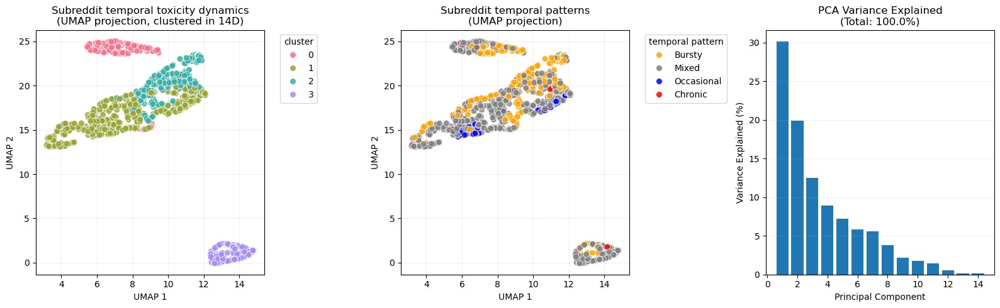

In [53]:
plot_cluster_results(result_df, reducer_name, feature_cols, cluster_labels, X_scaled, n_components_optimal)

In [54]:
create_interactive_plotly_visualization(result_df, reducer_name, feature_cols, n_components_optimal)


   Interactive plot created. Hover over points to see details.
  Each point shows: Subreddit name, Cluster interpretation, Temporal pattern, Event counts
  Controls: Scroll to zoom, drag to pan, double-click to reset view

  Interactive plot exported to: subreddit_clustering_interactive.html
  Ready for embedding in Jekyll website


### 4.3 Mega-Subreddit Analysis

In [55]:
mega_summary = analyze_mega_subreddits_in_clusters(result_df, n_top=15)


Analyzing 26 mega-subreddits included in clustering...

Top 15 Mega-Subreddits (now clustered):
                 cluster  total_tox_count_raw  src_tox_count_raw  \
subredditdrama         2               8244.0             7550.0   
bestof                 2               3016.0             2828.0   
askreddit              2               2641.0               61.0   
drama                  2               2464.0             2239.0   
circlebroke2           2               1649.0             1599.0   
worldnews              2               1384.0               12.0   
news                   2               1359.0               11.0   
shitpost               2               1284.0             1222.0   
todayilearned          2               1227.0              146.0   
pics                   2               1130.0                2.0   
funny                  2               1122.0               51.0   
shitredditsays         2               1120.0              904.0   
videos             

---
# THE FOLLOWING IS TO BE REMOVED BEFORE FINAL SUBMISSION

In [56]:
# This function extracts the result dataframe as a new dataframe and saves it to a CSV file.
def save_results_to_csv(result_df: pd.DataFrame, filename: str) -> None:
    """
    This function saves the result dataframe to a CSV file.
    
    Parameters:
    result_df (pd.DataFrame): The dataframe containing clustering results and features.
    filename (str): The name of the output CSV file.
    
    Returns:
    None
    """
    result_df.to_csv(filename, index=False)
    print(f"Results saved to {filename}")


save_results_to_csv(result_df, "subreddit_temporal_toxicity_clustering_results.csv")


Results saved to subreddit_temporal_toxicity_clustering_results.csv


In [57]:
# This function extracts the cluster column fron the result dataframe as a new series and saves it to a CSV file.

def save_cluster_assignments(result_df: pd.DataFrame, filename: str) -> None:
    """
    Save cluster assignments to a CSV file.
    
    Parameters:
    result_df (pd.DataFrame): Dataframe containing cluster assignments.
    filename (str): Output CSV file name.
    """
    cluster_series = result_df[['cluster']]
    cluster_series.to_csv(filename, index_label='subreddit')
    print(f"Cluster assignments saved to {filename}")

save_cluster_assignments(result_df, "subreddit_cluster_assignments.csv")

Cluster assignments saved to subreddit_cluster_assignments.csv
